<h1>Report</h1>

<h2>1. Business understanding</h2>

   - Määritellään ratkaistava liiketoimintaongelma (business problem).
   - Tavoitteena on selvittää analyysin päämäärä (goal), vaatimukset (requirements), rajoitteet (constraints) ja odotettu lopputulos (expected outcome).

The purpose of this project is to design and implement an image recognition system using our own captured images dataset from hand gestures, which are divided to 3 different classes: <b>Rock, Paper or Scissors</b>. 

The project will be carried out in stages, progressing from basic to more advanced convolutional neural network methods:<br> 
1. <b>Custom Convolutional Neural Network (CNN)</b> built from scratch using our own dataset.
2. <b>Feature Extraction using a pre-trained VGG16 model</b>, training only a custom classifier on top of the extracted features.
3. <b>Fine-tuned pre-trained model</b> with frozen lower layers and adapted upper layers.

Reporting and the model comparisons are done in this notebook. The goal is to compare which of these approaches work the best. 

<h2>2. Data understanding</h2>

   - Kerätään ja tutkitaan saatavilla olevaa dataa.
   - Tässä kartoitetaan datan ominaisuudet, kuten muuttujatyypit ja arvojakaumat, sekä mahdolliset laatuongelmat (quality issues), kuten puuttuvat arvot (missing values), poikkeamat (outliers) ja järjettömät arvot (nonsensical values).

As said, the data consists of our own images of hand gestures and each image belongs to one of the three classes: Rock, Paper, or Scissors. The total size of `the dataset is 297 images`, of which 191 images are used for training and 53 images each for training and validation. We can say, that the dataset we are working with is realy small.

The images contain different examples of the objects to be recognized. For examble different camera angles and lighting, while keeping the background simple as possible.  

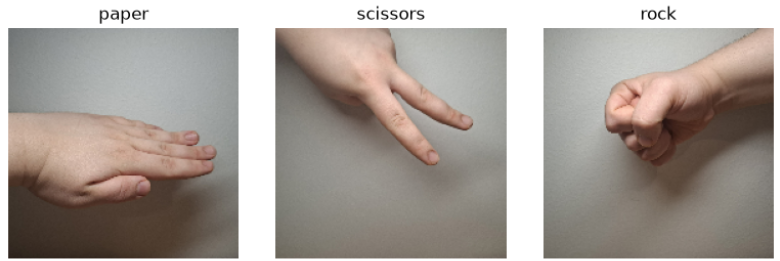

In addition to the training and validation data, we created images with slightly more complex backgrounds to investigate whether background complexity affects the model's performance.

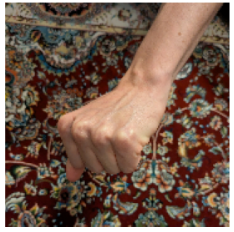    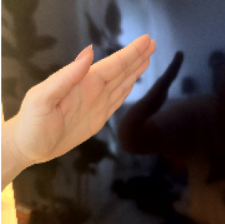

<h2>3. Data preparation</h2>

   - Data siivotaan, muunnetaan ja valitaan olennaiset piirteet (features).
   - Kaikki nämä vaiheet tulee dokumentoida niin tarkasti, että ne ovat myöhemmin täysin toistettavissa.

<h3>3.1 Shared data preparation</h3>

All images were configured into separate folders according to their classes and divided into training, testing, and validation folders. From where thee data is then loaded with `image_dataset_from_directory`.

Each model resizes every image to a consistent size of **180x180 pixels** and uses a batch size of **32**. The batch size determines how many images are processed by the model at a time. This ensures that the data is suitable for model training. The dataset split ratios are aproximately **(80%/ 10%/ 10%)**.

The folder structure is shown below.

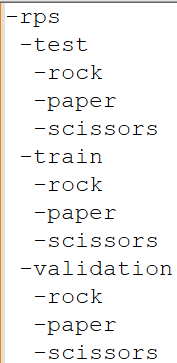



<h3>3.2 Differences in model architectures and data preparation</h3>

**CNN**<br>
In model 1, the images were normalized by dividing the pixel values by 255, scaling them to a range between 0 and 1. This helps the model process the image data more effectively. The test dataset was not shuffled in Models 2 and 3, allowing predictions to be matched with the correct labels.

**Feature extraction**<br>
For model 2, new important big step is added. Instead of using our own model built from scratch, we use the pre-trained VGG16 model for extracting the features. 

With the VG16 model, the images are passed once through the frozen VGG16 base, producing feature maps of shape (5, 5, 512). These extracted features are then saved and used for training our own model, significantly speeding up the training process.

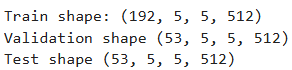

By using a pre-trained model, we want to determine whether we can improve the accuracy compared to the custom-built CNN model.

**Fine-tuned VGG16**<br>
Model 3 is very similar to model 2, but it has one significant difference. While in model 2 the weights remain completely unchanged, in model 3 we let a part of the VGG16 model learn more from our own data. 

This is done by freezing the lower floors `(frozen layers)`. The upper layers are left as `trainable layers`, meaning their weights can change during training. This way, we give the pre-trained model an opportunity to adapt better for our data. 

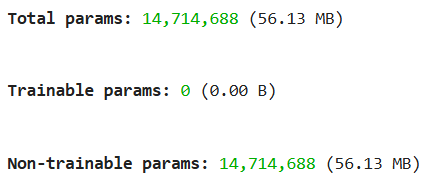

The image above shows that 4,714,688 parameters are non-trainable, belonging to the frozen layers. The remaining parameters are trainable, allowing the model to adjust its weights based on our own dataset.

<h2>4. Modeling</h2>

 - Valitaan koneoppimismenetelmä, opetetaan malli ja validoidaan se (validation).
 - Dokumentointiin on sisällytettävä tarkasti valittu menetelmä, käytetyt parametrit sekä mitattu mallin suorituskyky.
 - Millä perusteella tehty valinnat
 - Taulukko on hyvä viestimiseen
 - Ei tarvitse olla yksityiskohtainen, mutta selitetään miksi on päädytty lopputulokseen.
 - 
 - Vertaile mallien suorituskykyä testidatalla
 - Visualisoi tulokset ja oppimiskäyrät
 - Tutki väärin luokiteltuja kuvia
 - Reflektoi eri lähestymistapojen eroja

Three different approaches were explored to find a suitable model for classifying Rock, Paper, and Scissors images. The approaches were a `custom Convolutional Neural Network (CNN), feature extraction using a pre-trained VGG16 model, and fine-tuning a pre-trained model`.

The models were developed and trained using `Keras and TensorFlow`. Each model tried three different variants to find the best model structure. The model selection was based on validation results.

Each approach is described separately, including its architecture, main parameters and the reasons behind the selected configurations.

<h3>4.1 Model 1 - Custom CNN</h3>

**Architecture**<br>
The convolution layers are trainded from scratch using the Keras Sequential structure. Each variant consists of three blocks of `Conv2D`, followed by `MaxPooling2D` for finding important features from images, and to reduces the image size after each convolutional layer.

**Parameters**<br>
First two versions from the model used 32, 64, 128 as the Conv2D filter, but the last one had filter parameters as 16, 32, 64. In the last version the `dropout` was also reduced to 0.2 from 0.3, to reduce overfitting. 

Another difference between the versions is in the version 2, where flatten was replaced with `GlobalAveragePooling2D`. This reduces the number of parameters and makes the model smaller.

**Model version results**

  - V1: Validation accuracy: 28.3%, validation loss: 1.4285%
    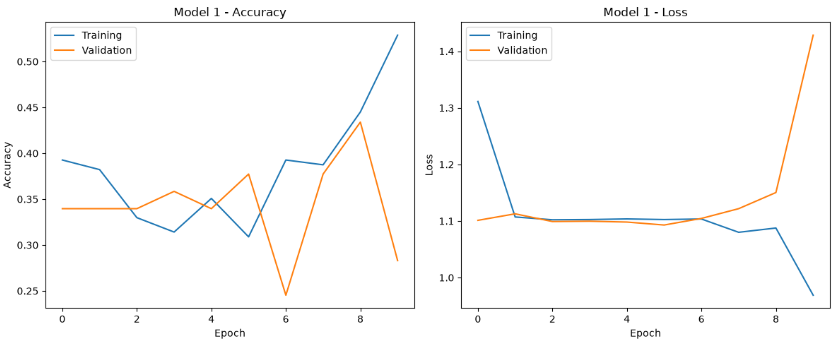
  - V2: Validation accuracy: 33.96%, validation accuracy: 1.0989%
    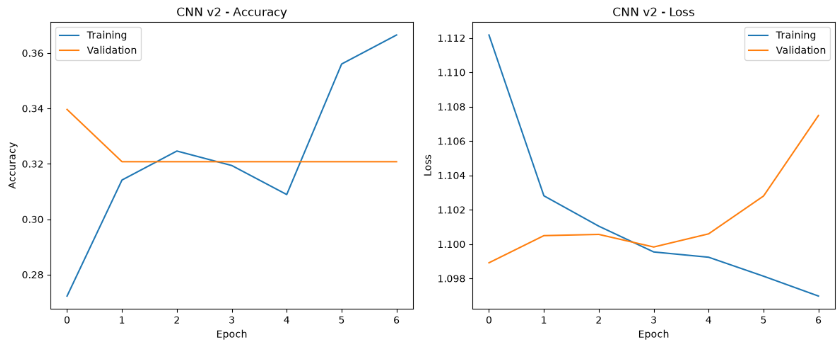
  - V3. Validation accuracy: 45.28%, validation accuracy: 1.9538%
    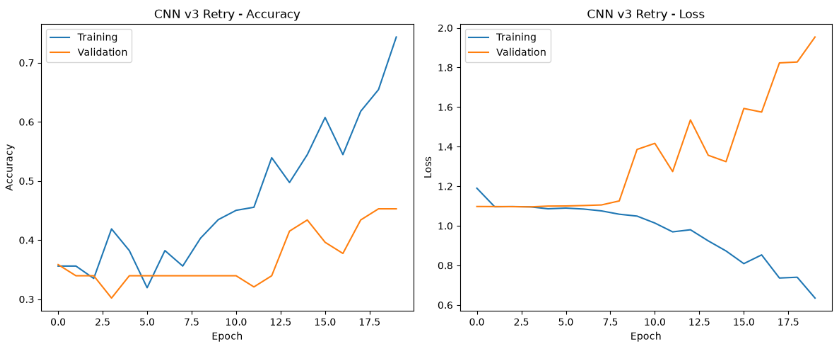

Version 3 achcieved the highest validation, but as well the highest validation loss.

**Conclusion**<br>
All variants use the same optimizer and loss so that only the architecture changes between them, which makes the comparison fair. But since the dataset is too small in this project, overfitting stayed as the main problem. Version 3 was chosen as the best performing CNN model.

<h3>4.2 Model 2 – VGG16 Feature Extraction</h3>

**Architecture**<br>
Model 2 uses pre-trained VGG16 network. It is trained on the ImageNet dataset and is used for running our dataset trough it once and then saving the results. The extracted features are then used in training our model. Results are saved to make our model training faster.

Each one changes optimizer or layers to find out what helps against overfitting, since the small dataset is the main problem.

The original VGG16 classification layer was removed, as a custom classifier was built on top of the extracted features. The custom classifier consists of five layers, through which the extracted features are passed to produce the final classification.

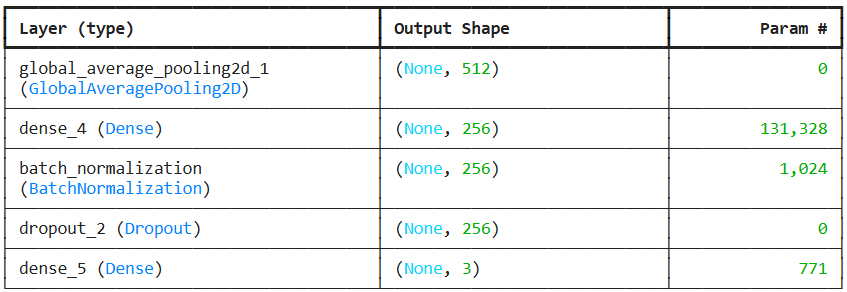

**Parameters**<br>
Three different model versions were tested, with main differences being:
  - V1: Flatter and RMSprop
  - V2: GlobalAveragePooling2D ja Adam.
  - V3: GlobalAveragePooling2D, BatchNormalization ja Dropout 0.4.

In all cases, a dense layer with 256 units was used, along with a three class softmax output. The maximum training duration was 100 epochs.

**Model version results**

  - V1: Validation accuracy ≈71%, validation loss ≈7.3%
  - V2: Validation accuracy ≈68%, validation accuracy ≈1.9%
  - V3. Validation accuracy ≈74%, validation accuracy ≈1.2%

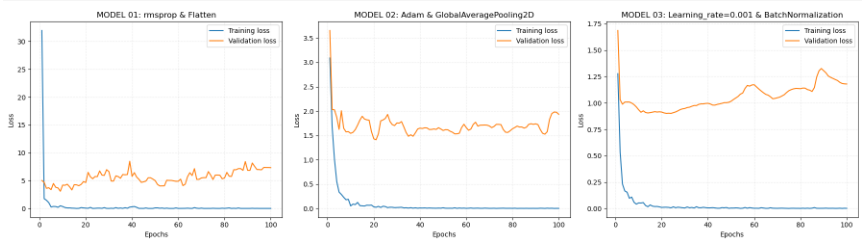

The third version performed the best in feature extraction model.

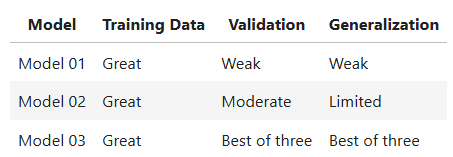

**Conclusion**<br>
All of the trained models learn very well from the training data, but perform poorly on the validation data.

The version 3 was chosen as the best version. Having the validation accuracy of 74%, and training loss 1.2.

<h3>4.3 Model 3 – Fine-Tuned VGG16</h3>

**Architecture**<br>
Model 3 uses the pre-trained VGG16 network as part of one complete model. Images go through data augmentation, VGG16 preprocessing, the VGG16 base and our own classifier.

Training had two phases. First VGG16 was frozen and only the classifier was trained, then the best classifier was trained further with the last four VGG16 layers unfrozen and a small learning rate 0.0001. Meaning, the best performing version is then fine tuned.

**Parameters**<br>
Four classifier versions were tested, and the best one will be fine tuned:
  - V1: Dense 256, Dropout 0.5
  - V2: Dense 256 and 128, Dropout 0.5 and 0.3
  - V3: V2 with L2 regularization (0.001) and EarlyStopping
  - V4: V3 without EarlyStopping

All used RMSprop and a maximum of 50 epochs. A checkpoint saved the model with the lowest validation loss. Fine-tuning used 30 epochs.

**Model version results**
  - V1: Validation accuracy: 0.7358%, validation loss: 2.3668%
    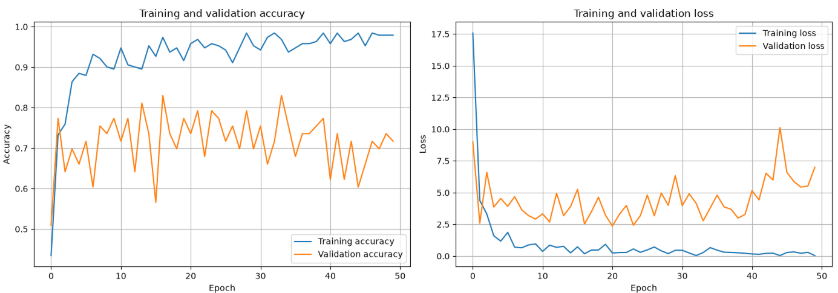
  - V2: Validation accuracy: 0.7547%, validation accuracy: 1.8082%
    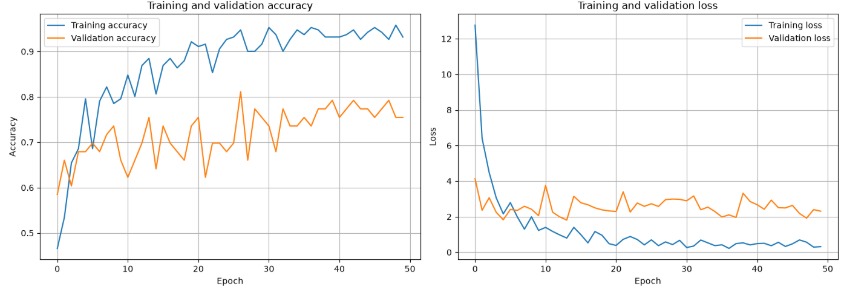
  - V3. Validation accuracy: 0.8113%, validation accuracy: 1.4836%
    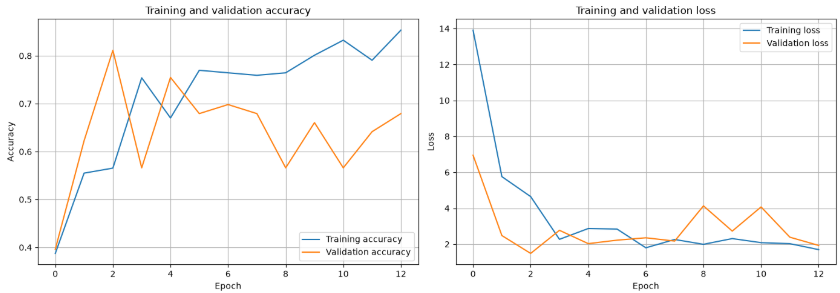
  - V4: Validation accuracy: 0.7547%, validation accuracy: 2.5404%
    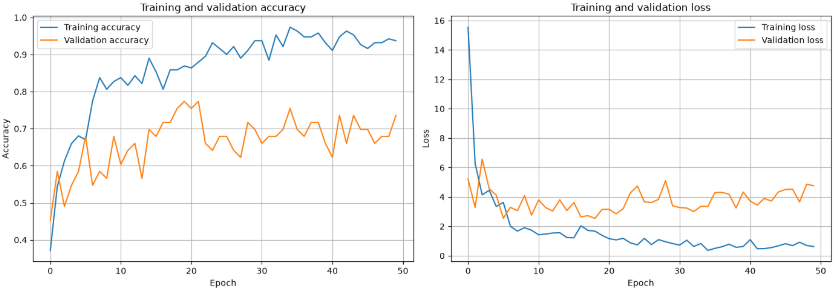

Yet again, the third version from a model was seen as the best version. It will be the one, that ends up being fine-tuned.
  - V3 (Fine-tuned): Validatoin accuracy: 0.7358%, validation loss: 1.4269%
Unfortunately, the fine-tuning didn't give any better result for us in this case.

**Conclusion**<br>
Our last model performed almos identicaly compared to the Feature Extraction model. Version 3 from this model might have had the best validation results without fine-tuning, but it we wanted to add it to see how it performes. It it will be chosen as the version that goes trough testing.

<h2>5. Evaluation</h2>

 - Arvioidaan mallin todellinen onnistuminen.
 - Selvitetään, kuinka hyvin malli vastaa sille alun perin asetettuihin liiketoimintavaatimuksiin (business requirements).<br>
 - Ei katsota mallin suorituskykyä (tämä tehdään kappaleessa 4), vaan palataan takaisin kappaleeseen 1. ja millä tavalla saavutetut tulokset vertautuu alkuperäisiin tavoitteisiin.
 - `Misclassified images: the assignment asks for them, but notebook 3 doesn’t show any. Notebook 1 only shows validation errors.`

<h2>5. Evaluation</h2>

The project objective was partially achieved, as a functional image recognition model was built and trained. However, the models performance fell short of expectations because of our small dataset.

**Test results**<br>
Next we will show the results, that each version from the 3 models got, using the same test data.
  - Model 1, V3: Test accuracy: 37.74%, test loss: 1.9397
  - Model 2, V3: Test accuracy ≈72%, test loss ≈1.2%
  - Model 3, V3 (Fine-tuned): Test accuracy: 0.6981%, test loss: 1.7368% 

The own CNN performed clearly worst. With under 200 training images it could not learn good features from scratch. Both pre-trained models reached about 70 %, which is almost twice as high. Even though the test accuracy is nearly the same for model 2 and 3, model 2 had smaller test loss rate. So based on test result, `model 2` was the best performing one.

**Misclassified images**

**Model 1 – Own CNN**<br>
Nine misclassified images were inspected. The errors were spread over all three classes, so there was no single confusing class. Most of the images had dark backgrounds or some kind of an pattern. Some hand angles seemed to be hard to understand as well. This suggests the model relies on background and shape details instead of the hand gesture itself.

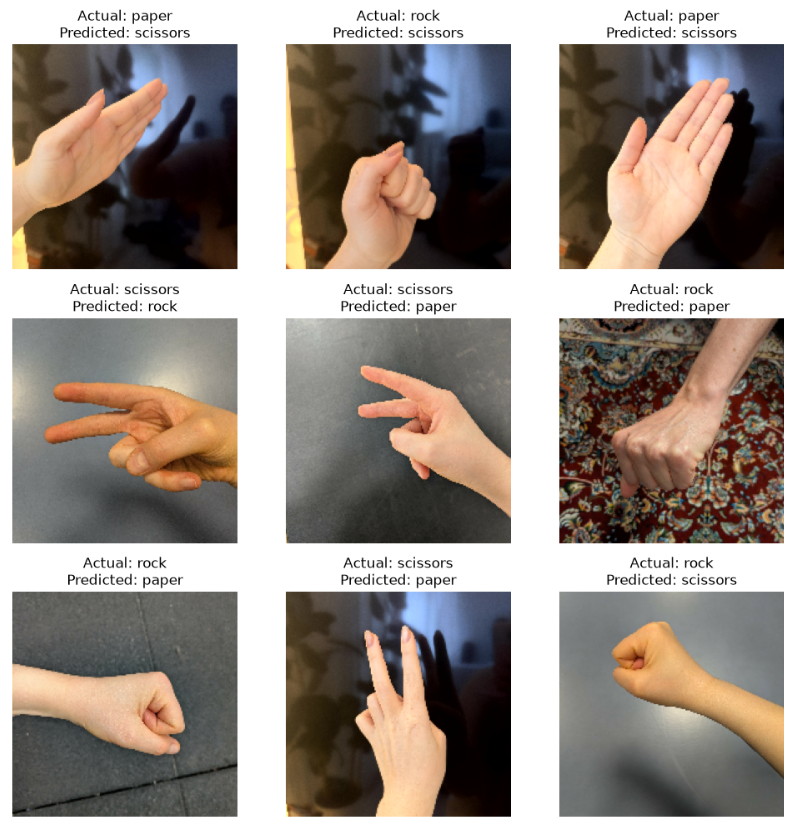

**Model 2 – VGG16 feature extraction**<br>
Predictions were checked for the first six test images. Five were classified correctly with a probability near 1.0. The sixth was a paper image misclassified as rock with about 94% confidence. The model is therefore often very confident even when it is wrong, which fits its overfitting.

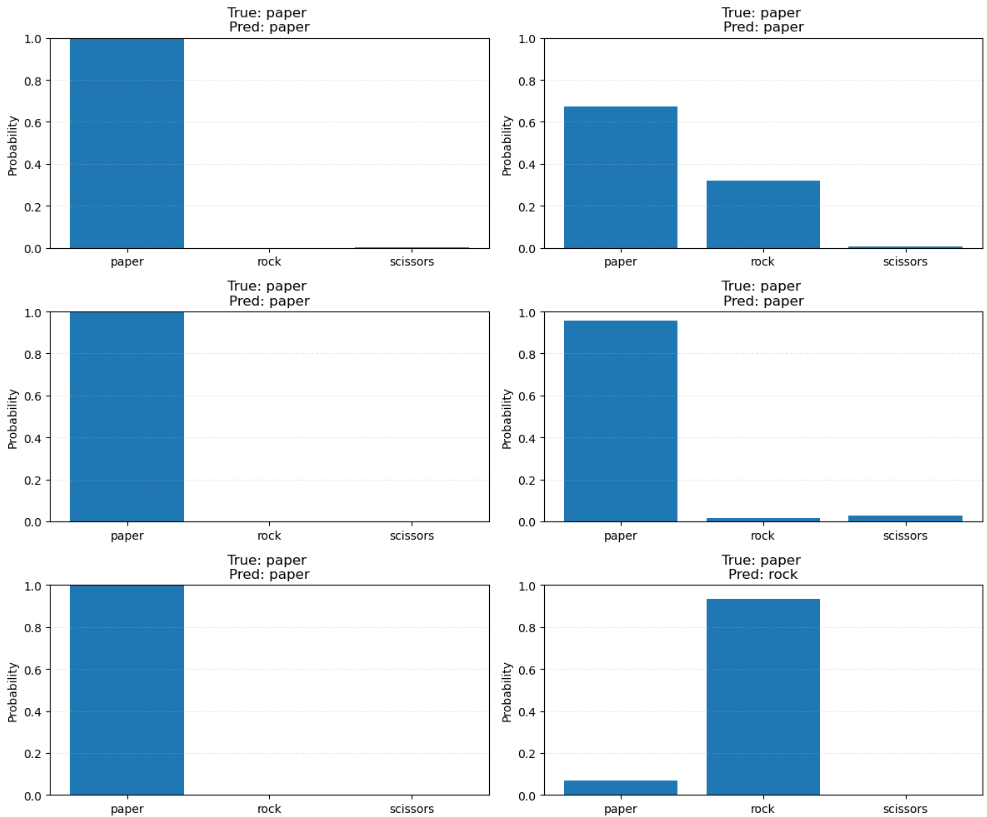

**Model 3 – Fine-tuned VGG16**<br>
In model 3 a confusion matrix was used. It shows that paper was the hardest class. 7 of 19 paper images were classified as rock and 2 as scissors. Rock was mistaken for paper twice and for scissors twice, and scissors was mistaken for paper once and for rock twice. Correct classifications were paper 10/19, rock 13/17 and scissors 14/17. In a sample of six test images all were correct, and the model was uncertain only for one paper image (62 % paper, 38 % scissors).

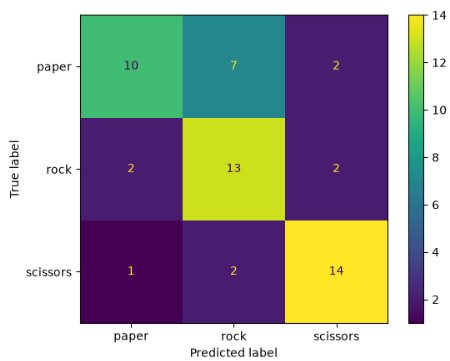

<h2>6. Deployment</h2>

The project goal, comparing three approaches on our own images, was achieved. The pre-trained VGG16 approaches (Models 2 and 3) are clearly the best, but none of the models is accurate enough for real use. The best candidate for further development is the fine-tuned model, which overfits the less even though it did not improve test accuracy/loss compared to model 2. For now, model 2 is the simplest and fastest way to reach about the same result.

Since overfitting remained in every model, in the future more data is needed for creating more accurate models, pefore deployment could be a possibility.